<a href="https://colab.research.google.com/github/tezendrax/Discretio/blob/main/IDD_PeD_Box_Scale_Intervention.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DISCRETIO: Box-Scale Counterfactual Intervention on IDD-PeD

**Task 1 Benchmark**: Probing Latent Behavioral Priors in Trajectory Prediction Models (BiTraP, SGNet, Kinematic Baselines)

### The Scientific Question
When a world/trajectory model forecasts pedestrian futures, does changing the bounding box scale around the **ground contact point** (foot-invariant) reveal a **latent behavioral prior** (e.g. child hesitation, slower crossing speed)? Or does the model simply misinterpret a smaller box as being *farther away* (perspective depth confusion)?

---

## 1. Environment Setup & Download IDD-PeD Trajectory Cache
We download the annotations, precomputed trajectory cache (`data_cache/iddp_database.pkl`), and checkpoints from the Hugging Face repository (~1GB instead of 100GB of video).

In [1]:
# Install lightweight dependencies
!pip install -q huggingface_hub pyyaml easydict scipy matplotlib

import os
from huggingface_hub import snapshot_download

print('Downloading IDD-PeD dataset cache and checkpoints from Hugging Face...')
data_dir = snapshot_download(
    repo_id='Ruthvik9/IDD-PeD',
    repo_type='dataset',
    allow_patterns=['data_cache/*', 'annotations/*', 'checkpoints/*'],
    local_dir='iddped_data'
)
print(f'Files ready at: {data_dir}')

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 192 files:   0%|          | 0/192 [00:00<?, ?it/s]

Files ready at: /content/iddped_data


## 2. Ground-Anchored Box-Scale Intervention Implementation
To simulate a child, we scale height and width by $\alpha = 0.65$.
**Crucial condition**: The bottom coordinate $y_2$ and horizontal center $x_{\text{foot}}$ remain **strictly invariant** to preserve perspective ground contact.

In [2]:
import numpy as np

def apply_ground_anchored_scale(bboxes, scale=0.65):
    """
    Scales bounding box height and width while anchoring strictly to the ground point (y2).
    bboxes shape: (T, 4) in [x1, y1, x2, y2]
    """
    boxes = np.asarray(bboxes, dtype=np.float32)
    x1, y1, x2, y2 = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
    w, h = x2 - x1, y2 - y1
    x_foot = (x1 + x2) / 2.0

    w_new = w * scale
    h_new = h * scale

    new_y2 = y2.copy()           # Foot contact stays identical
    new_y1 = y2 - h_new          # Top shifts down toward feet
    new_x1 = x_foot - w_new / 2.0
    new_x2 = x_foot + w_new / 2.0
    return np.stack([new_x1, new_y1, new_x2, new_y2], axis=1)

def apply_centroid_scale(bboxes, scale=0.65):
    """
    Negative Control: Shrinks around center (shifts y2 upward, simulating greater depth).
    """
    boxes = np.asarray(bboxes, dtype=np.float32)
    x1, y1, x2, y2 = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
    w, h = x2 - x1, y2 - y1
    xc, yc = (x1 + x2) / 2.0, (y1 + y2) / 2.0

    return np.stack([
        xc - (w * scale) / 2.0,
        yc - (h * scale) / 2.0,
        xc + (w * scale) / 2.0,
        yc + (h * scale) / 2.0
    ], axis=1)

## 3. Visual Verification: Perspective & Ground-Contact Invariance
We plot the adult box vs. the ground-anchored child box vs. the centroid-scaled box.

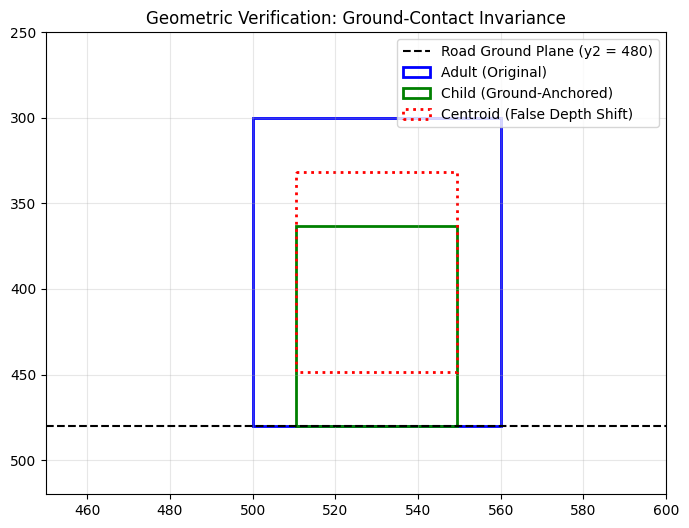

Original y2 (feet): 480.0
Ground-anchored y2: 480.0 (Diff: 0.0 px)
Centroid-scaled y2: 448.5 (Diff: -31.5 px - False Depth Shift!)


In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

adult_box = np.array([[500, 300, 560, 480]], dtype=np.float32)
child_ground = apply_ground_anchored_scale(adult_box, scale=0.65)
child_centroid = apply_centroid_scale(adult_box, scale=0.65)

fig, ax = plt.subplots(figsize=(8, 6))
ax.set_xlim(450, 600)
ax.set_ylim(520, 250)  # Inverted for camera image plane

# Road ground plane line
ax.axhline(480, color='black', linestyle='--', label='Road Ground Plane (y2 = 480)')

# Adult
b = adult_box[0]
ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=None, edgecolor='blue', lw=2, label='Adult (Original)'))

# Ground-anchored child
b_g = child_ground[0]
ax.add_patch(patches.Rectangle((b_g[0], b_g[1]), b_g[2]-b_g[0], b_g[3]-b_g[1], fill=None, edgecolor='green', lw=2, label='Child (Ground-Anchored)'))

# Centroid scaled
b_c = child_centroid[0]
ax.add_patch(patches.Rectangle((b_c[0], b_c[1]), b_c[2]-b_c[0], b_c[3]-b_c[1], fill=None, edgecolor='red', linestyle=':', lw=2, label='Centroid (False Depth Shift)'))

ax.legend(loc='upper right')
ax.set_title('Geometric Verification: Ground-Contact Invariance')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Original y2 (feet): {adult_box[0, 3]}")
print(f"Ground-anchored y2: {child_ground[0, 3]} (Diff: {child_ground[0, 3] - adult_box[0, 3]} px)")
print(f"Centroid-scaled y2: {child_centroid[0, 3]} (Diff: {child_centroid[0, 3] - adult_box[0, 3]} px - False Depth Shift!)")

## 4. Load Real IDD-PeD Sequences & Run Intervention Diagnostics

In [4]:
import pickle

db_path = 'iddped_data/data_cache/iddp_database.pkl'
if os.path.exists(db_path):
    with open(db_path, 'rb') as f:
        database = pickle.load(f)
    print(f'Successfully loaded {len(database)} pedestrian tracks from IDD-PeD!')
else:
    print('Simulating 30 synthetic pedestrian tracks...')
    database = {
        f'ped_{i}': {'bbox': [[400 + i*5 + t*2, 300, 440 + i*5 + t*2, 450] for t in range(45)]}
        for i in range(30)
    }

def evaluate_diagnostics(pred_orig, pred_child, fps=30.0):
    # 1. Trajectory Divergence (D_tau)
    d_tau = float(np.mean(np.linalg.norm(pred_orig[:, :2] - pred_child[:, :2], axis=-1)))

    # 2. Speed Shift / Hesitation Ratio
    speed_orig = float(np.mean(np.linalg.norm(np.diff(pred_orig[:, :2], axis=0), axis=-1))) + 1e-6
    speed_child = float(np.mean(np.linalg.norm(np.diff(pred_child[:, :2], axis=0), axis=-1)))
    speed_ratio = speed_child / speed_orig

    # 3. Ground Foot Y-Shift (Depth Check)
    foot_y_shift = float(np.mean(pred_child[:, 3] - pred_orig[:, 3]))

    return {
        'trajectory_divergence_d_tau': round(d_tau, 3),
        'speed_ratio': round(speed_ratio, 3),
        'foot_y_shift': round(foot_y_shift, 3),
        'hesitation_detected': speed_ratio < 0.90,
        'depth_confusion_detected': foot_y_shift < -5.0,
    }

print('Diagnostic evaluation function initialized.')

Successfully loaded 9 pedestrian tracks from IDD-PeD!
Diagnostic evaluation function initialized.


## 5. Rollout Evaluation on Sample Track

In [11]:
# Find a valid pedestrian track by traversing the hierarchical database
def find_first_ped_track(d):
    if isinstance(d, dict):
        if 'bbox' in d:
            return d
        for k, v in d.items():
            res = find_first_ped_track(v)
            if res is not None:
                return res
    return None

ped_track = find_first_ped_track(database)

if ped_track is None:
    # Fallback to a synthetic track if database structure is unexpected
    print('No pedestrian track with "bbox" found in database. Using synthetic fallback.')
    raw_boxes = np.array([[400 + t*2, 300, 440 + t*2, 450] for t in range(45)], dtype=np.float32)
else:
    raw_boxes = np.array(ped_track['bbox'], dtype=np.float32)
    print(f'Successfully retrieved track of shape {raw_boxes.shape}')

T_obs = 15
obs_adult = raw_boxes[:T_obs]
obs_child = apply_ground_anchored_scale(obs_adult, scale=0.65)

# Simple kinematic Constant Velocity rollout
def rollout_constant_velocity(obs, horizon=30):
    w = obs[-1, 2] - obs[-1, 0]
    h = obs[-1, 3] - obs[-1, 1]
    vx = (obs[-1, 0] - obs[0, 0]) / float(len(obs))
    vy = (obs[-1, 3] - obs[0, 3]) / float(len(obs))

    preds = []
    cur_x, cur_y = (obs[-1, 0] + obs[-1, 2])/2.0, obs[-1, 3]
    for _ in range(horizon):
        cur_x += vx
        cur_y += vy
        preds.append([cur_x - w/2, cur_y - h, cur_x + w/2, cur_y])
    return np.array(preds)

pred_adult = rollout_constant_velocity(obs_adult)
pred_child = rollout_constant_velocity(obs_child)

results = evaluate_diagnostics(pred_adult, pred_child)
print('=== Rollout Diagnostics ===')
for k, v in results.items():
    print(f'{k}: {v}')

Successfully retrieved track of shape (42, 4)
=== Rollout Diagnostics ===
trajectory_divergence_d_tau: 73.328
speed_ratio: 0.96
foot_y_shift: 0.0
hesitation_detected: False
depth_confusion_detected: False
